In [9]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [10]:
DATA_PATH = 'Walmart DataSet.csv'
OUTPUT_DIR = Path('walmart_capstone_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

In [24]:
import pandas as pd

DATA_PATH = "Walmart DataSet.csv"
df = pd.read_csv(DATA_PATH)

print(df.head())

   Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1  05-02-2010    1643690.90             0        42.31       2.572   
1      1  12-02-2010    1641957.44             1        38.51       2.548   
2      1  19-02-2010    1611968.17             0        39.93       2.514   
3      1  26-02-2010    1409727.59             0        46.63       2.561   
4      1  05-03-2010    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  


In [38]:
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns.tolist())
df.head()

(6435, 8)
['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [39]:
required_columns = [
    "Store", "Date", "Weekly_Sales", "Holiday_Flag",
    "Temperature", "Fuel_Price", "CPI", "Unemployment"
]

missing_columns = [col for col in required_columns if col not in df.columns]      #Check required columns

print("Missing columns:", missing_columns)

Missing columns: []


Convert the date

In [42]:
df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

Convert numeric columns

In [43]:
numeric_columns = [
    "Store", "Weekly_Sales", "Holiday_Flag",
    "Temperature", "Fuel_Price", "CPI", "Unemployment"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [44]:
print(df.isnull().sum())  #Check missing values

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64


Handle missing values

In [45]:
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

df = df.dropna(subset=["Date", "Store", "Weekly_Sales"])

Remove duplicates and sort data

In [46]:
df = df.drop_duplicates().copy()

df["Store"] = df["Store"].astype(int)
df["Holiday_Flag"] = df["Holiday_Flag"].astype(int)

df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

In [47]:
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df.head()

Dataset shape: (6435, 8)
Missing values:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Duplicate rows: 0


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


Dataset overview and statistics

In [48]:
print("Dataset Overview")
print("Total records:", len(df))
print("Total stores:", df["Store"].nunique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

df.describe().round(2)

Dataset Overview
Total records: 6435
Total stores: 45
Date range: 2010-02-05 to 2012-10-26


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.00,6435,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00
mean,23.00,2011-06-17 00:00:00,1046964.88,0.07,60.66,3.36,171.58,8.00
min,1.00,2010-02-05 00:00:00,209986.25,0.00,-2.06,2.47,126.06,3.88
25%,12.00,2010-10-08 00:00:00,553350.10,0.00,47.46,2.93,131.74,6.89
50%,23.00,2011-06-17 00:00:00,960746.04,0.00,62.67,3.44,182.62,7.87
75%,34.00,2012-02-24 00:00:00,1420158.66,0.00,74.94,3.74,212.74,8.62
max,45.00,2012-10-26 00:00:00,3818686.45,1.00,100.14,4.47,227.23,14.31
std,12.99,NaN,564366.62,0.26,18.44,0.46,39.36,1.88


Weekly sales distribution

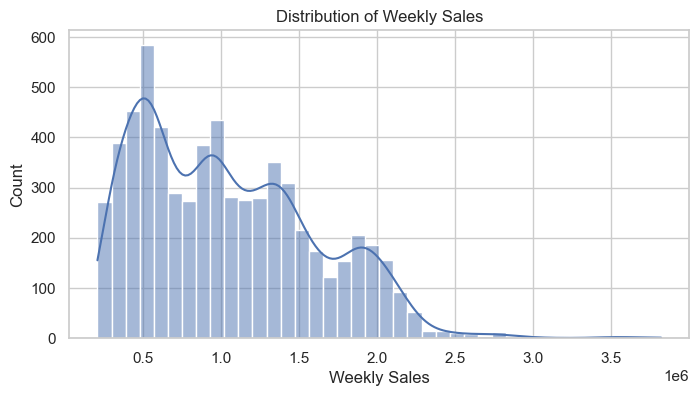

In [49]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Weekly_Sales"], bins=40, kde=True)
plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.show()

Correlation matrix

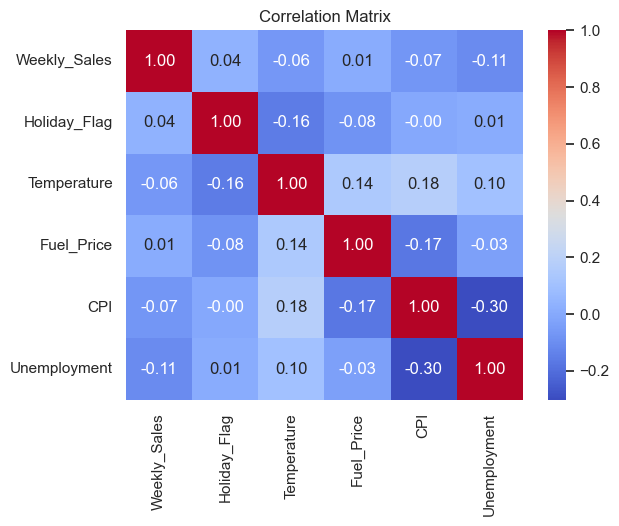

Correlation with Weekly Sales:
Weekly_Sales    1.000
Holiday_Flag    0.037
Fuel_Price      0.009
Temperature    -0.064
CPI            -0.073
Unemployment   -0.106
Name: Weekly_Sales, dtype: float64


In [50]:
cols = ["Weekly_Sales", "Holiday_Flag", "Temperature",
        "Fuel_Price", "CPI", "Unemployment"]

sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

print("Correlation with Weekly Sales:")
print(df[cols].corr()["Weekly_Sales"].sort_values(ascending=False).round(3))

Analyze Outliers

In [51]:
#Calculate outlier limits
q1 = df["Weekly_Sales"].quantile(0.25)
q3 = df["Weekly_Sales"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

In [52]:
# Identify and save outliers
outliers = df[
    (df["Weekly_Sales"] < lower_bound) |
    (df["Weekly_Sales"] > upper_bound)
]

print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Total Outliers:", len(outliers))

outliers.to_csv(
    OUTPUT_DIR / "weekly_sales_outliers.csv",
    index=False
)

Lower Bound: -746862.73
Upper Bound: 2720371.49
Total Outliers: 34


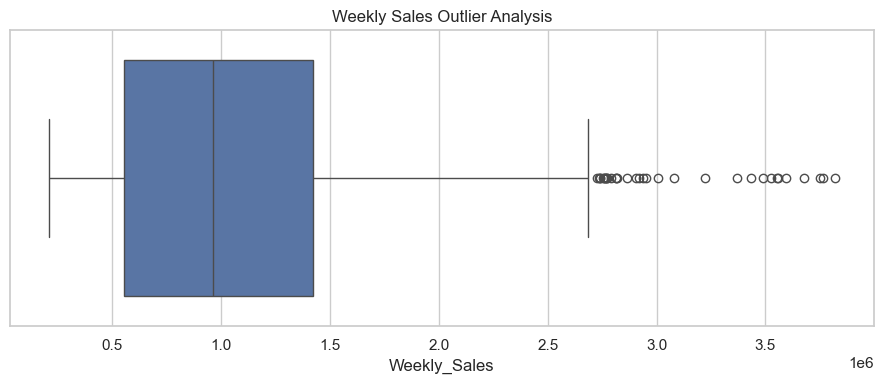

In [53]:
# Visualize outliers

plt.figure(figsize=(9, 4))
sns.boxplot(x=df["Weekly_Sales"])
plt.title("Weekly Sales Outlier Analysis")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weekly_sales_boxplot.png")
plt.show()

Analyze Business Questions

In [54]:
# Store performance
store_performance = df.groupby("Store").agg(
    Total_Sales=("Weekly_Sales", "sum"),
    Average_Weekly_Sales=("Weekly_Sales", "mean"),
    Median_Weekly_Sales=("Weekly_Sales", "median"),
    Number_of_Weeks=("Weekly_Sales", "count")
).sort_values("Total_Sales", ascending=False)

store_performance.to_csv(OUTPUT_DIR / "store_performance.csv")

print("Top 5 Stores:")
display(store_performance.head(5).round(2))

print("Bottom 5 Stores:")
display(store_performance.tail(5).sort_values("Total_Sales").round(2))

best_store = store_performance["Total_Sales"].idxmax()
worst_store = store_performance["Total_Sales"].idxmin()

print("Best Store:", best_store)
print("Worst Store:", worst_store)
print("Sales Difference:",
      round(store_performance.loc[best_store, "Total_Sales"]
            - store_performance.loc[worst_store, "Total_Sales"], 2))

Top 5 Stores:


,Total_Sales,Average_Weekly_Sales,Median_Weekly_Sales,Number_of_Weeks
Store,,,,
20,3.013978e+08,2107676.87,2053165.41,143
4,2.995440e+08,2094712.96,2073951.38,143
14,2.889999e+08,2020978.40,2004330.30,143
13,2.865177e+08,2003620.31,1958823.56,143
2,2.753824e+08,1925751.34,1879107.31,143


Bottom 5 Stores:


,Total_Sales,Average_Weekly_Sales,Median_Weekly_Sales,Number_of_Weeks
Store,,,,
33,37160221.96,259861.69,258427.39,143
44,43293087.84,302748.87,298080.45,143
5,45475688.90,318011.81,310338.17,143
36,53412214.97,373511.99,373267.58,143
38,55159626.42,385731.65,380870.09,143


Best Store: 20
Worst Store: 33
Sales Difference: 264237570.5


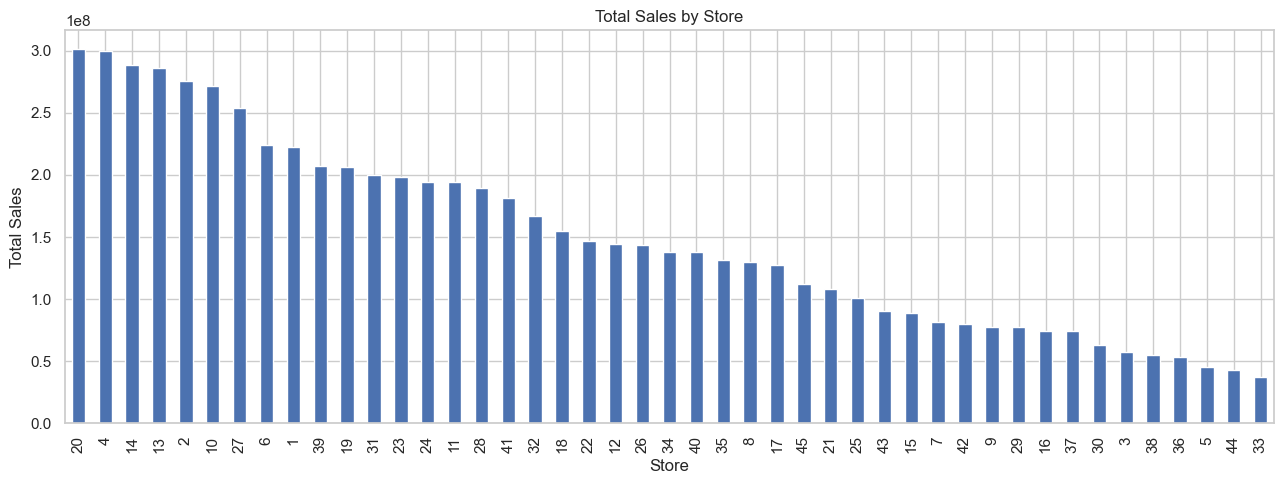

In [55]:
# 2. Total Sales by Store
store_performance["Total_Sales"].sort_values(
    ascending=False
).plot(kind="bar", figsize=(13, 5), title="Total Sales by Store")

plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "total_sales_by_store.png")
plt.show()

In [56]:
# 3. Unemployment vs Weekly Sales
unemployment_corr = df.groupby("Store").apply(
    lambda x: x["Unemployment"].corr(x["Weekly_Sales"])
    if x["Unemployment"].nunique() > 1 else np.nan
).dropna().sort_values()

unemployment_corr = unemployment_corr.rename(
    "Unemployment_Sales_Correlation"
).reset_index()

unemployment_corr.to_csv(
    OUTPUT_DIR / "unemployment_sales_by_store.csv", index=False
)

display(unemployment_corr.head(5).round(3))
print("More negative correlation means a stronger negative association.")

,Store,Unemployment_Sales_Correlation
0,38,-0.785
1,44,-0.780
2,39,-0.385
3,42,-0.356
4,41,-0.351


More negative correlation means a stronger negative association.


Month
1      923884.55
2     1053199.80
3     1013309.23
4     1026761.56
5     1031714.02
6     1064324.59
7     1031747.58
8     1048017.45
9      989335.35
10     999632.12
11    1147265.90
12    1281863.63
Name: Weekly_Sales, dtype: float64

Highest sales month: 12
Lowest sales month: 1


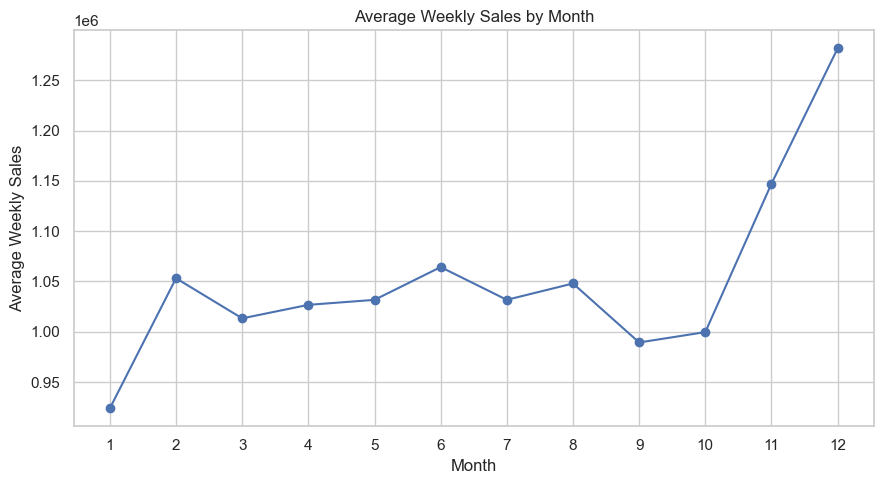

Average sales by holiday flag:


Holiday_Flag
0    1041256.38
1    1122887.89
Name: Weekly_Sales, dtype: float64

In [57]:
# 4. Monthly Sales and Holiday Analysis
df["Month"] = df["Date"].dt.month

monthly_sales = df.groupby("Month")["Weekly_Sales"].mean()

display(monthly_sales.round(2))

print("Highest sales month:", monthly_sales.idxmax())
print("Lowest sales month:", monthly_sales.idxmin())

monthly_sales.plot(
    marker="o", figsize=(9, 5), title="Average Weekly Sales by Month"
)
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "average_sales_by_month.png")
plt.show()

print("Average sales by holiday flag:")
display(df.groupby("Holiday_Flag")["Weekly_Sales"].mean().round(2))

Temperature correlation: -0.064
CPI correlation: -0.073


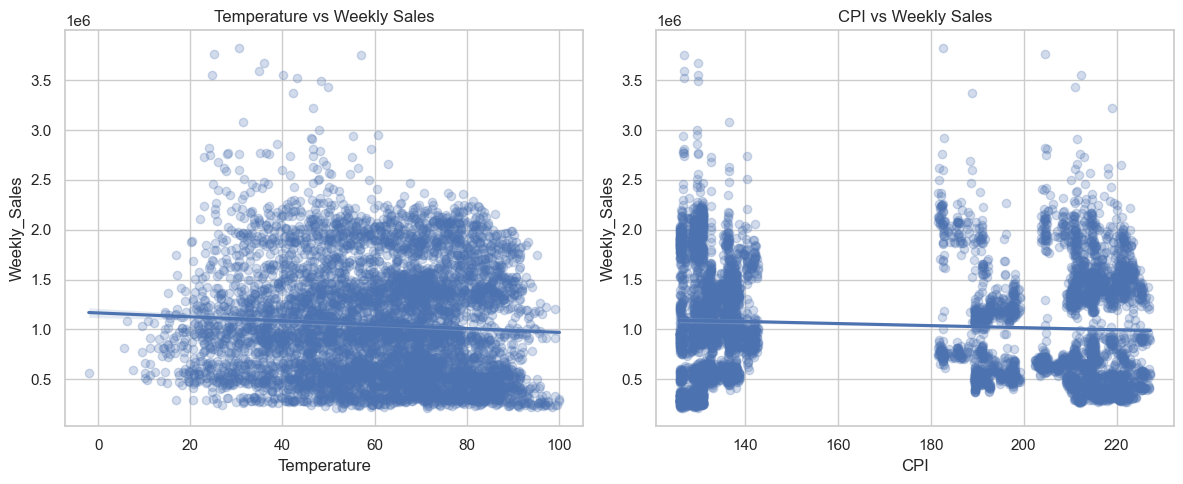

In [58]:
# 5. Temperature and CPI Analysis
correlations = df[
    ["Weekly_Sales", "Temperature", "CPI"]
].corr()["Weekly_Sales"]

print("Temperature correlation:", round(correlations["Temperature"], 3))
print("CPI correlation:", round(correlations["CPI"], 3))

impact_by_store = df.groupby("Store").apply(
    lambda x: pd.Series({
        "Temperature_Correlation":
            x["Temperature"].corr(x["Weekly_Sales"]),
        "CPI_Correlation":
            x["CPI"].corr(x["Weekly_Sales"]),
        "Unemployment_Correlation":
            x["Unemployment"].corr(x["Weekly_Sales"])
    })
).reset_index()

impact_by_store.to_csv(
    OUTPUT_DIR / "economic_factors_by_store.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(data=df, x="Temperature", y="Weekly_Sales",
            scatter_kws={"alpha": 0.25}, ax=axes[0])
axes[0].set_title("Temperature vs Weekly Sales")

sns.regplot(data=df, x="CPI", y="Weekly_Sales",
            scatter_kws={"alpha": 0.25}, ax=axes[1])
axes[1].set_title("CPI vs Weekly Sales")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "temperature_cpi_vs_sales.png")
plt.show()

Forecast All Stores

In [60]:
#Forecast function

def forecast_all_stores(df, forecast_weeks=12):
    forecast_frames = []

    for store_id, group in df.groupby("Store"):
        series = (
            group.groupby("Date")["Weekly_Sales"]
            .sum()
            .sort_index()
            .asfreq("7D")
            .interpolate(method="time")
            .ffill()
            .bfill()
        )

        try:
            model = ExponentialSmoothing(
                series,
                trend="add",
                damped_trend=True,
                seasonal="add",
                seasonal_periods=52,
                initialization_method="estimated"
            )
            fitted_model = model.fit(optimized=True)
            model_name = "Holt-Winters Seasonal"

        except Exception:
            model = ExponentialSmoothing(
                series,
                trend="add",
                initialization_method="estimated"
            )
            fitted_model = model.fit(optimized=True)
            model_name = "Holt Linear Trend"

        forecast_values = fitted_model.forecast(forecast_weeks)

        forecast_frames.append(pd.DataFrame({
            "Store": store_id,
            "Date": forecast_values.index,
            "Forecast_Weekly_Sales": np.maximum(
                forecast_values.values, 0
            ),
            "Model": model_name
        }))

    return pd.concat(forecast_frames, ignore_index=True)

In [61]:
#Generate and save forecasts
forecasts = forecast_all_stores(df)

forecasts.to_csv(
    OUTPUT_DIR / "12_week_sales_forecast_all_stores.csv",
    index=False
)

print("Total forecast rows:", len(forecasts))
print("Stores forecasted:", forecasts["Store"].nunique())

forecasts.head(15)

Total forecast rows: 540
Stores forecasted: 45


,Store,Date,Forecast_Weekly_Sales,Model
0,1,2012-11-02,1.685050e+06,Holt-Winters Seasonal
1,1,2012-11-09,1.612113e+06,Holt-Winters Seasonal
2,1,2012-11-16,1.586748e+06,Holt-Winters Seasonal
3,1,2012-11-23,2.064970e+06,Holt-Winters Seasonal
4,1,2012-11-30,1.644541e+06,Holt-Winters Seasonal
5,1,2012-12-07,1.803390e+06,Holt-Winters Seasonal
6,1,2012-12-14,1.972869e+06,Holt-Winters Seasonal
7,1,2012-12-21,2.439185e+06,Holt-Winters Seasonal
8,1,2012-12-28,1.495472e+06,Holt-Winters Seasonal
9,1,2013-01-04,1.564233e+06,Holt-Winters Seasonal


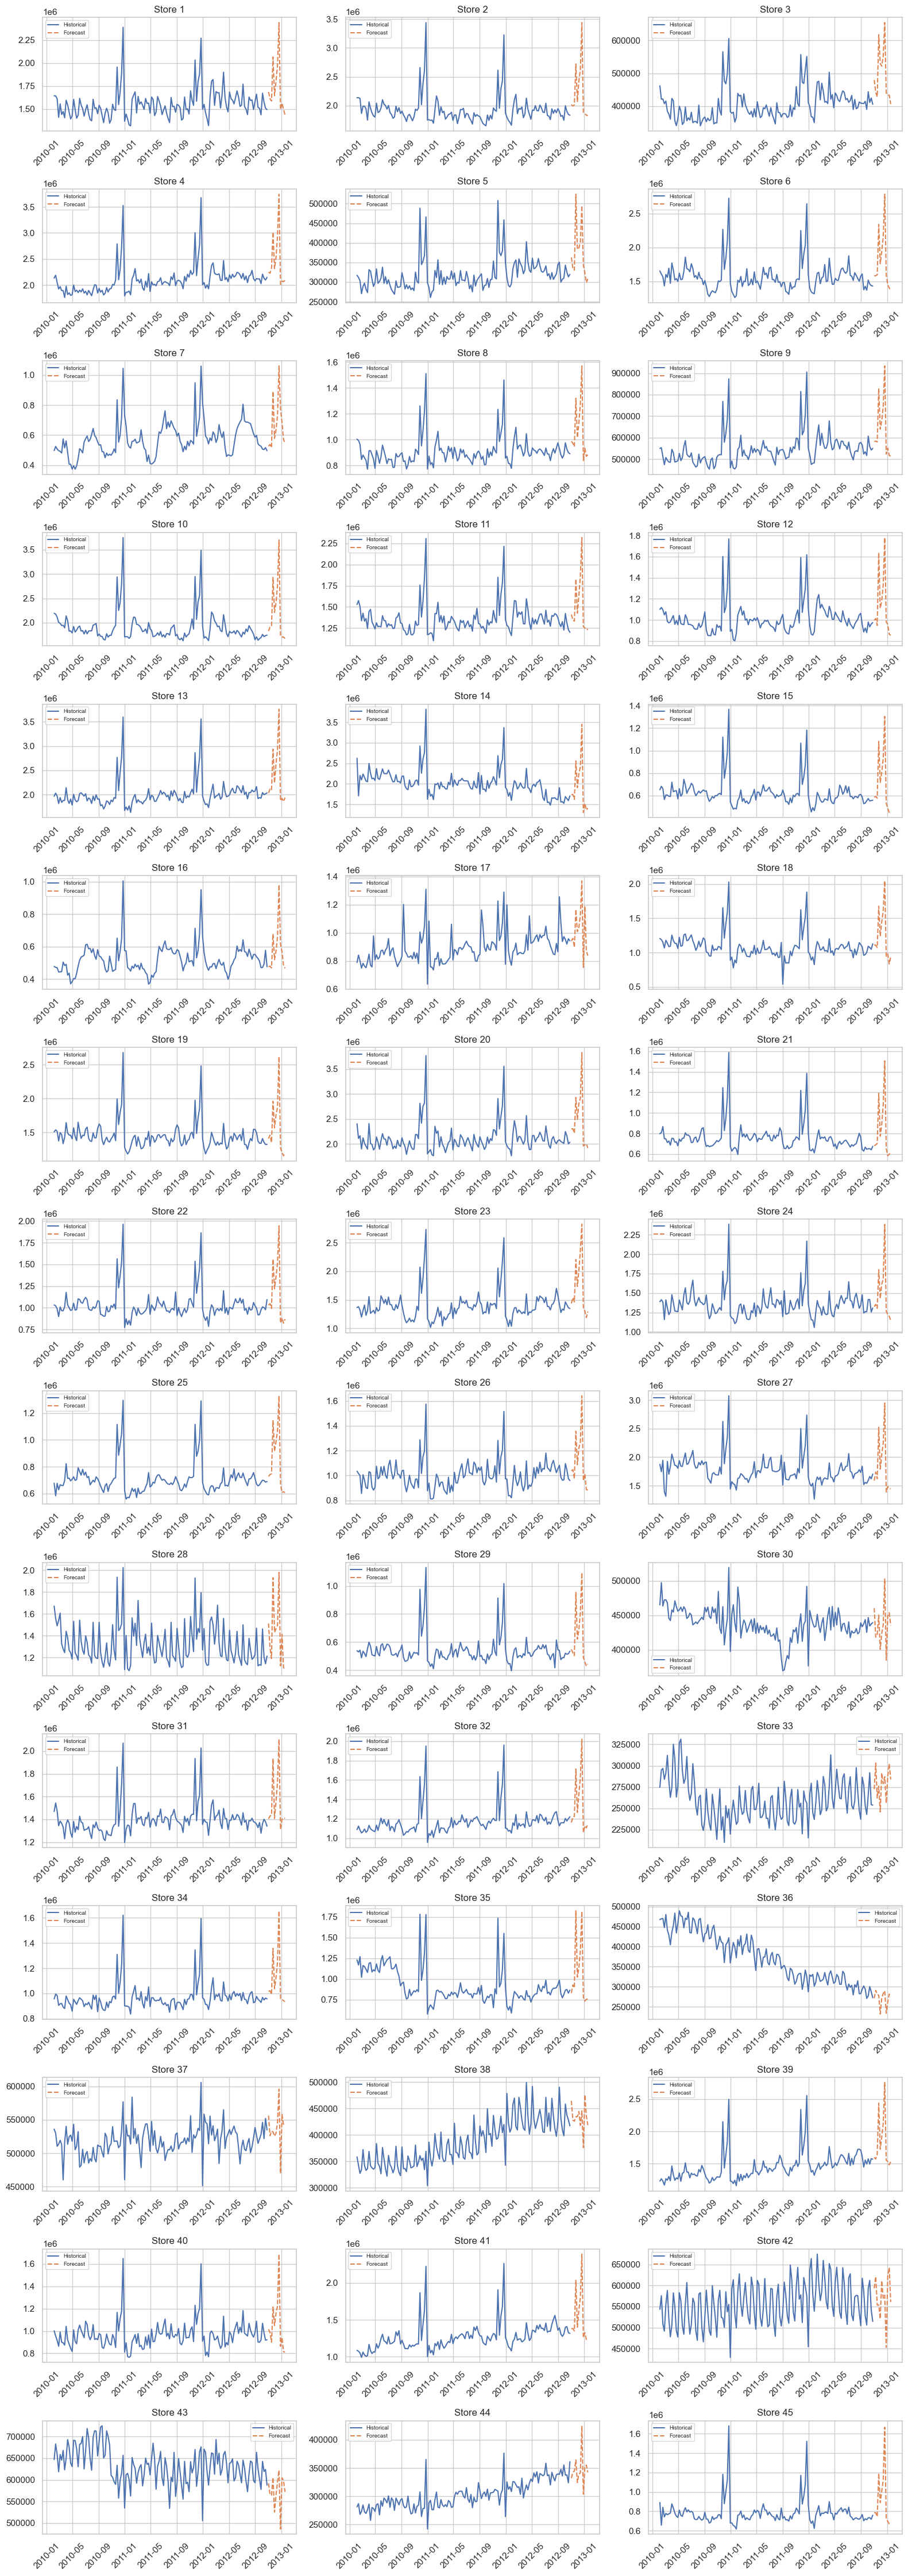

In [62]:
#Plot forecasts for all stores 
store_ids = sorted(forecasts["Store"].unique())

ncols = 3
nrows = int(np.ceil(len(store_ids) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, nrows * 3),
    squeeze=False
)

for i, store_id in enumerate(store_ids):
    ax = axes[i // ncols, i % ncols]

    history = df[df["Store"] == store_id].sort_values("Date")
    future = forecasts[forecasts["Store"] == store_id]

    ax.plot(history["Date"], history["Weekly_Sales"],
            label="Historical")
    ax.plot(future["Date"], future["Forecast_Weekly_Sales"],
            linestyle="--", label="Forecast")

    ax.set_title(f"Store {store_id}")
    ax.tick_params(axis="x", labelrotation=45)
    ax.legend(fontsize=7)

for j in range(len(store_ids), nrows * ncols):
    axes[j // ncols, j % ncols].axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "12_week_forecast_all_stores.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [63]:
#Check the forecast results
print("Forecast date range:",
      forecasts["Date"].min(),
      "to",
      forecasts["Date"].max())

print("\nForecast count per store:")
print(forecasts.groupby("Store").size())

print("\nForecast summary:")
print(forecasts["Forecast_Weekly_Sales"].describe().round(2))

Forecast date range: 2012-11-02 00:00:00 to 2013-01-18 00:00:00

Forecast count per store:
Store
1     12
2     12
3     12
4     12
5     12
6     12
7     12
8     12
9     12
10    12
11    12
12    12
13    12
14    12
15    12
16    12
17    12
18    12
19    12
20    12
21    12
22    12
23    12
24    12
25    12
26    12
27    12
28    12
29    12
30    12
31    12
32    12
33    12
34    12
35    12
36    12
37    12
38    12
39    12
40    12
41    12
42    12
43    12
44    12
45    12
dtype: int64

Forecast summary:
count        540.00
mean     1180553.83
std       699781.60
min       231713.92
25%       578014.12
50%      1065798.18
75%      1597345.27
max      3829213.87
Name: Forecast_Weekly_Sales, dtype: float64


In [69]:
print("Data loaded:", df.shape)
print("Stores:", df["Store"].nunique())
print("Forecast rows:", len(forecasts))
print(forecasts.head())

Data loaded: (6435, 8)
Stores: 45
Forecast rows: 540
   Store       Date  Forecast_Weekly_Sales                  Model
0      1 2012-11-02           1.685050e+06  Holt-Winters Seasonal
1      1 2012-11-09           1.612113e+06  Holt-Winters Seasonal
2      1 2012-11-16           1.586748e+06  Holt-Winters Seasonal
3      1 2012-11-23           2.064970e+06  Holt-Winters Seasonal
4      1 2012-11-30           1.644541e+06  Holt-Winters Seasonal
